# 02 - QoL_Stress exploration (Phase 1)

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
M = ROOT / 'results' / 'metrics'; F = ROOT / 'results' / 'figures'; P = ROOT / 'data' / 'processed'
insp = json.load(open(ROOT/'results/reports/phase1_inspection.json'))['qol_stress']

## Files, rows, missing values

In [2]:
pd.DataFrame({k: {kk: v[kk] for kk in ('n_rows','n_columns','exact_duplicate_rows')} | {'participants': v.get('n_participants')} for k, v in insp['files'].items()}).T

,n_rows,n_columns,exact_duplicate_rows,participants
participants,66,5,0,66
ecg,132,13,0,66
eda,20094,6,1542,64
hr_second,54462,3,0,66
hr_minute,2131,3,0,66
hr_summary,264,6,0,66
pss,66,17,0,66
stai,132,24,0,66


## Verifying the ECG sampling rate from the data
The release does not state it. If the rate is right, the heart rate computed from detected R-peaks must match the device's own `heart_rate` field.

In [3]:
from src.data.qol_loader import load_qol, parse_waveform
from src.preprocessing.qol_signals import process_ecg
d = load_qol(); rows = []
for _, r in d['ecg'].head(20).iterrows():
    x = parse_waveform(r.waveform_samples).samples
    rows.append({'device_hr': r.heart_rate, **{f'hr_at_{fs}Hz': process_ecg(x, fs)['ecg_hr'] for fs in (125, 250, 500)}})
pd.DataFrame(rows).round(1)

,device_hr,hr_at_125Hz,hr_at_250Hz,hr_at_500Hz
0,46,68.0,46.8,94.5
1,46,75.5,53.3,91.9
2,78,41.0,81.2,162.9
3,71,46.0,72.1,144.3
4,94,46.1,91.6,178.8
5,88,44.7,89.4,171.5
6,65,49.2,65.3,129.4
7,65,46.3,67.5,133.4
8,75,54.9,76.6,152.8
9,65,71.5,64.9,129.0


## Session timeline (minutes relative to the relax-phase STAI)
Fitbit HR has no phase column; this timeline is what the phase windows are anchored on.

In [4]:
pd.DataFrame(insp['timeline_minutes_relative_to_stai_relax'])

,pss,stai_relax,stai_stress,ecg_relax,ecg_stress,fitbit_first,fitbit_last
count,66.0,66.0,66.0,66.0,66.0,66.0,66.0
mean,-13.0,0.0,12.3,1.2,10.2,-19.9,12.4
std,6.2,0.0,2.4,24.1,16.9,4.2,5.5
min,-52.5,0.0,9.1,-45.4,-31.9,-30.0,-18.6
25%,-13.6,0.0,10.8,-6.6,5.0,-21.7,10.6
50%,-12.6,0.0,11.9,-5.8,6.2,-19.8,12.1
75%,-11.9,0.0,12.9,-5.3,8.0,-18.4,14.0
max,9.5,0.0,20.6,113.1,66.6,-1.0,29.2


In [5]:
insp['ecg_time_consistency']

{'ecg_relax_within_15min_before_stai_relax': 55,
 'ecg_stress_between_stai_relax_and_stai_stress': 58,
 'ecg_relax_outliers_pid': ['Q11',
  'Q13',
  'Q16',
  'Q24',
  'Q33',
  'Q38',
  'Q41',
  'Q48',
  'Q49',
  'Q58',
  'Q59'],
 'ecg_stress_outliers_pid': ['Q10',
  'Q23',
  'Q26',
  'Q40',
  'Q41',
  'Q48',
  'Q49',
  'Q61']}

## Duplicated ECG recordings and EDA availability

In [6]:
display(insp['ecg']['duplicated_reading_ids']); insp['eda_sessions']

{'770c2cd0-b709-11ef-8080-808080808080': {'pids': ['Q15', 'Q48'],
  'phases': ['stress', 'stress'],
  'identical_waveforms': True,
  'reading_times': ['16:14:35', '12:14:35']},
 'eb7e45f0-b707-11ef-8080-808080808080': {'pids': ['Q15', 'Q48'],
  'phases': ['relax', 'relax'],
  'identical_waveforms': True,
  'reading_times': ['16:03:31', '12:03:31']}}

{'participants_with_any_eda': 64,
 'both_phases': 60,
 'relax_only': 4,
 'stress_only': 0,
 'participants_without_eda': ['Q15', 'Q44'],
 'rows_per_session': {'count': 124.0,
  'mean': 162.0,
  'std': 1.3,
  'min': 158.0,
  '25%': 162.0,
  '50%': 162.0,
  '75%': 163.0,
  'max': 164.0}}

## Manipulation check

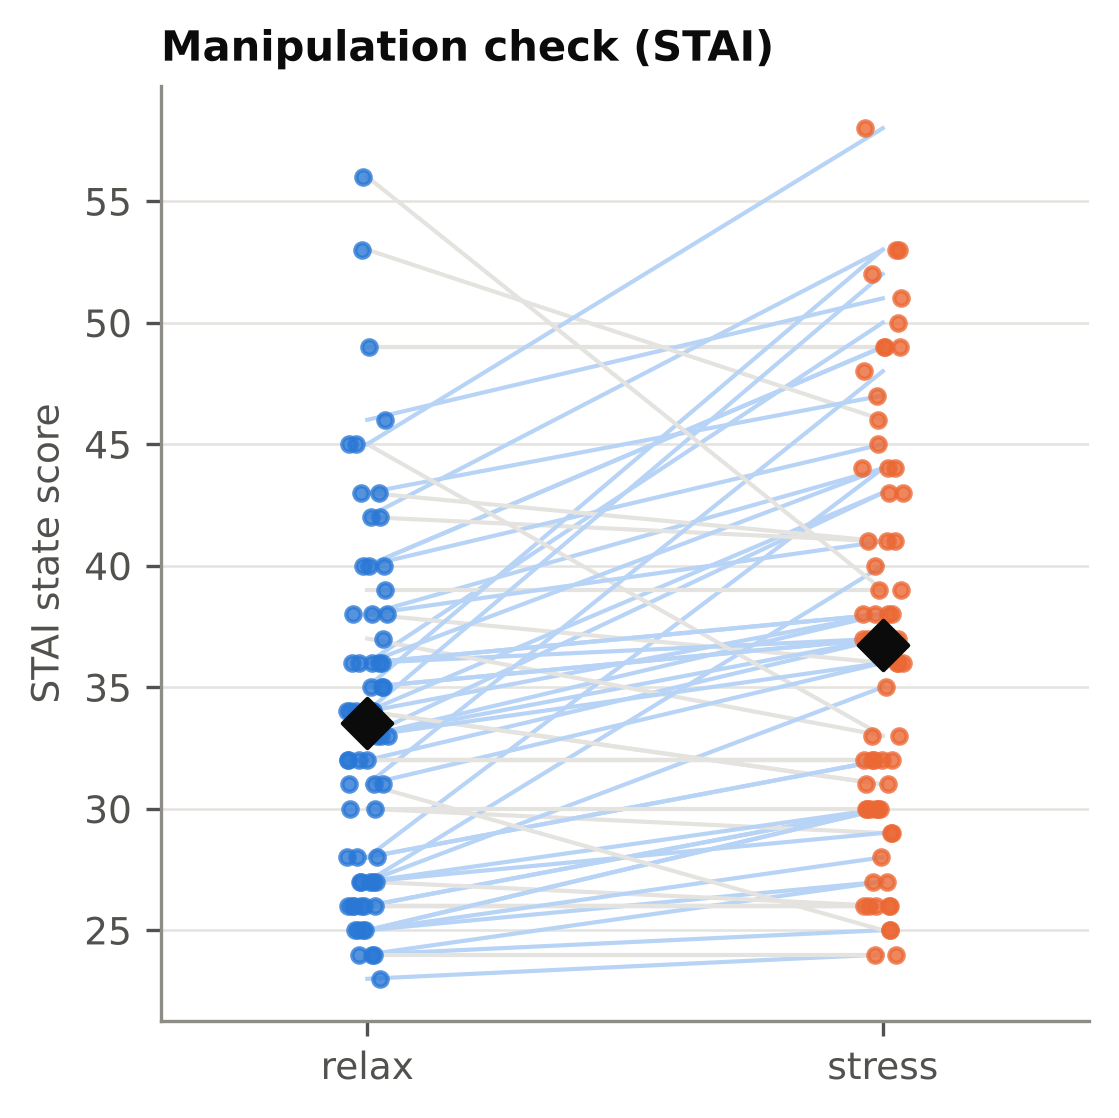

{'n': 66,
 'stai_relax_mean': 33.515151515151516,
 'stai_stress_mean': 36.74242424242424,
 'mean_increase': 3.227272727272727,
 'cohen_dz': 0.5113011450560497,
 'wilcoxon_p': 2.6266517240502323e-05,
 'n_increase': 43,
 'n_equal': 11,
 'n_decrease': 12}

In [7]:
display(Image(F/'qol_stai_manipulation.png', width=380)); json.load(open(M/'qol_manipulation_check.json'))